In [2]:
import numpy as np

# Input: house area
X = np.array([
    [500],
    [800],
    [1000],
    [1200],
    [1500]
])

# Actual house prices
y = np.array([25, 40, 50, 60, 75])

print(X.shape)
print(y.shape)

(5, 1)
(5,)


In [3]:
X = np.array([
    [500, 1, 10],
    [800, 2, 8],
    [1000, 2, 5],
    [1200, 3, 3],
    [1500, 3, 1]
])
print(X)
print(X.shape)
m, n = X.shape
print(m,n)

[[ 500    1   10]
 [ 800    2    8]
 [1000    2    5]
 [1200    3    3]
 [1500    3    1]]
(5, 3)
5 3


![Description](images/screenshot1.png)

#


In [4]:
m, n = X.shape

theta = np.zeros(n + 1)

print(theta)


[0. 0. 0. 0.]


Why n + 1?

Because we have three features and one additional parameter for the intercept.

Why zeros?

Because we need a starting point for optimization. We will update these parameters during training.

![Description](images/LinearRegThroughOrigin.png)

![Description](images/LinearRegintercept.png)

The fitted line attempts to minimize the vertical distances (residuals) between observed points and predicted points.

For ordinary least squares, the best-fitting line minimizes the sum of squared residuals. Gradient Descent is one way to find its parameters.

![Description](images/LinearRegCostFunction.png)

![Description](images/LinearRegCostExample.png)

![Description](images/LinearRegGradientDescent.png)

![Description](images/LinearRegGradientDescent2.png)

Implement Linear Regression using NumPy
Now let's write our own implementation.

I am deliberately using a one-dimensional theta array here. It makes the matrix operations easier to understand.

In [5]:
import numpy as np


class LinearRegressionScratch:

    def __init__(self, learning_rate=0.1, iterations=2000):

        # Controls how big each parameter update is
        self.learning_rate = learning_rate

        # Maximum number of training iterations
        self.iterations = iterations

        self.theta = None
        self.loss_history = []

    def fit(self, X, y):

        # Number of samples and input features
        m, n = X.shape
        print("m is training row ",m, "n is the feature ",n)

        # Add a column of ones for the intercept
        X = np.c_[np.ones(m), X]
        print("Added intercept as Bias to features",X)

        # Initialize bias + feature weights
        self.theta = np.zeros(n + 1)
        print("Assign initial Theta value as ",self.theta)

        for i in range(self.iterations):

            # 1. Forward pass: calculate predictions
            predictions = X @ self.theta

            # 2. Calculate prediction errors
            errors = predictions - y

            # 3. Calculate cost
            cost = np.sum(errors ** 2) / (2 * m)

            self.loss_history.append(cost)

            # 4. Calculate gradients
            gradients = (X.T @ errors) / m

            # 5. Update parameters
            self.theta -= self.learning_rate * gradients

        return self

    def predict(self, X):

        m = X.shape[0]

        # Add intercept column
        X = np.c_[np.ones(m), X]

        return X @ self.theta


# -------------------------------
# Training data
# -------------------------------

X = np.array([
    [0.5],
    [0.8],
    [1.0],
    [1.2],
    [1.5]
])

y = np.array([25, 40, 50, 60, 75])

# Train model
model = LinearRegressionScratch(
    learning_rate=0.1,
    iterations=2000
)

model.fit(X, y)

# Print learned parameters
print("Theta:", model.theta)
print("Final cost:", model.loss_history[-1])

# Predict
predictions = model.predict(
    np.array([[1.8], [2.0]])
)

print("Predictions:", predictions)


m is training row  5 n is the feature  1
Added intercept as Bias to features [[1.  0.5]
 [1.  0.8]
 [1.  1. ]
 [1.  1.2]
 [1.  1.5]]
Assign initial Theta value as  [0. 0.]
Theta: [3.10128401e-04 4.99997073e+01]
Final cost: 5.178466147366404e-09
Predictions: [89.99978334 99.9997248 ]


Code	Why is it used?
m, n = X.shape	    Extract sample and feature counts
np.ones(m)	        Create intercept column
np.c_[...]	        Join intercept column with feature matrix
np.zeros(n + 1)	    Initialize bias and weights
X @ theta	        Matrix multiplication for predictions
predictions - y	    Calculate errors
np.sum(errors ** 2)	Sum squared errors
X.T	                Transpose input matrix
X.T @ errors	Calculate gradients for all parameters
theta -= ...	Update parameters using gradient descent

The matrix dimensions – understand this carefully
For our five samples and one feature:
Operation	Shape
Original X	(5, 1)
X after adding intercept	(5, 2)
Theta	(2,)
Predictions	(5,)
Actual y	(5,)
Errors	(5,)
X transpose	(2, 5)
Gradients	(2,)

![Description](images/RawLinRegEquation.png)

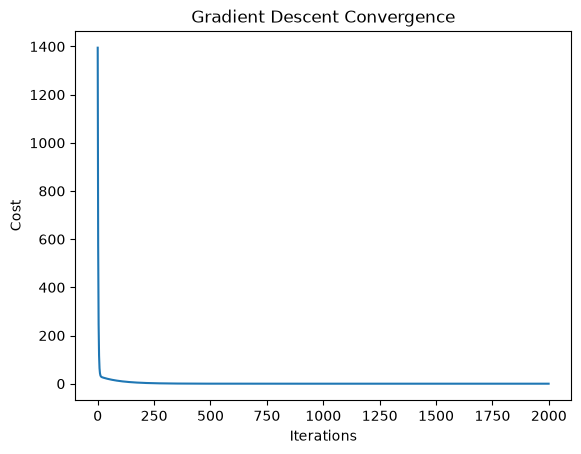

In [6]:
import matplotlib.pyplot as plt

plt.plot(model.loss_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence")
plt.show()

Compare wit hScikit-learn

In [7]:
from sklearn.linear_model import LinearRegression

sk_model = LinearRegression()

sk_model.fit(X, y)

print("Intercept:", sk_model.intercept_)
print("Coefficient:", sk_model.coef_)

print(
    "Prediction:",
    sk_model.predict(np.array([[2.0]]))
)

Intercept: -7.105427357601002e-15
Coefficient: [50.]
Prediction: [100.]
